# Sowing comparison: SIMPLACE rule vs the sowing network (torchcrop, MSWX)

Five torchcrop runs on the same export, seasons, calibrated crops and code
(`submit/sowing/submit_sowing_comparison.sh`). Only two inputs vary, the sowing
table and the emergence thermal sum:

| Arm | Sowing | `tsumem` | Isolates |
|---|---|---|---|
| **A0** | SIMPLACE rule (euval table) | calibrated per region | the old method |
| A1 | SIMPLACE rule | PEP725 fit | `tsumem` alone |
| B1 | network | calibrated per region | sowing alone (expect emergence too late: double counting) |
| **B0** | network | PEP725 fit | the new method |
| C | per-cell median of B0's table | PEP725 fit | does the *weather response* help, or only the level? |

**Hold-outs.** PEP725 trained the network (sowing + emergence) and fitted
`tsumem`, so every PEP725 score here uses the **test station blocks** only
(`sowing_network/pep725_split.parquet`). CLMS and CyBench scores are reported
per calibration split; read `test`.

**Significance.** Cells within a unit and seasons within a year are not
independent, so arms are compared on **paired per-unit** absolute errors with
a bootstrap over units.

## 0. Setup

In [1]:
import json
import logging
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cropmodelling4eu.evaluation import production as prod
from cropmodelling4eu.evaluation.doy import doy_difference
from cropmodelling4eu.evaluation.fullrun import load_runs
from cropmodelling4eu.evaluation.plots import EUROPE_PROJECTION, country_choropleth, save
from cropmodelling4eu.evaluation.regions import load_admin_polygons
from cropmodelling4eu.evaluation.style import use_poster_style
from cropmodelling4eu.sowing.config import load_sowing_config
from cropmodelling4eu.sowing.targets import pep725_seasons

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_poster_style()

DATA = Path("/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu")
ROOT = Path(os.environ.get("SOWING_COMPARISON_DIR", DATA / "runs/winter_wheat/sowing_comparison"))
SOWING = load_sowing_config(os.environ.get("SOWING_CONFIG"))
CALIBRATION = Path(os.environ.get("CALIBRATION_DIR", SOWING.calibration_dir))
YEARS = (2000, 2024)
OUT = ROOT / "evaluation"
FIGURES, TABLES = OUT / "figures", OUT / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

LABELS = {"A0": "A0 rule + cal. tsumem (old)", "A1": "A1 rule + PEP tsumem",
          "B1": "B1 net + cal. tsumem", "B0": "B0 net + PEP tsumem (new)", "C": "C net climatology",
          "D": "D yield-max sowing (bound)"}
COLOURS = {"A0": "#7f7f7f", "A1": "#bcbd22", "B1": "#9467bd", "B0": "#1f9e89", "C": "#d62728", "D": "#ff7f0e"}
ARMS = [a for a in LABELS if (ROOT / a / "torchcrop" / "torchcrop_europe.parquet").is_file()]
provenance = {a: json.loads((ROOT / a / "provenance.json").read_text()) for a in ARMS}
pd.DataFrame(provenance).T[["sowing_file", "crops_dir", "tsumem_source", "fallback_crop_overrides", "submitted"]]

,sowing_file,crops_dir,tsumem_source,fallback_crop_overrides,submitted
A0,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,calibrated per region,None,2026-11-12T11:00:42+00:00
A1,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,PEP725 fit,tsumem=128.0 tbasem=0.0,2026-11-12T13:38:52+00:00
B1,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,calibrated per region,None,2026-11-12T13:39:01+00:00
B0,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,PEP725 fit,tsumem=128.0 tbasem=0.0,2026-11-12T13:39:07+00:00
C,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,PEP725 fit,tsumem=128.0 tbasem=0.0,2026-11-12T13:39:16+00:00
D,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,/data01/FDS/muduchuru/Data/SIMPLACE/cropmodell...,PEP725 fit,tsumem=128.0 tbasem=0.0,2026-11-12T14:55:28+00:00


In [2]:
runs = {
    arm: load_runs(ROOT / arm / "_no_simplace.parquet",
                   ROOT / arm / "torchcrop" / "torchcrop_europe.parquet", years=YEARS)["torchcrop"]
    for arm in ARMS
}
tsumem = json.loads((SOWING.out_dir / "tsumem.json").read_text())
print({a: f"{len(f):,} cell-seasons" for a, f in runs.items()})
print(f"PEP725 tsumem {tsumem['tsumem']:.0f} C d  (train blocks, n {tsumem['n']}, MAE {tsumem['mae_days']:.1f} d)")

{'A0': '1,711,524 cell-seasons', 'A1': '1,711,524 cell-seasons', 'B1': '1,717,125 cell-seasons', 'B0': '1,717,125 cell-seasons', 'C': '1,717,125 cell-seasons', 'D': '1,717,125 cell-seasons'}
PEP725 tsumem 128 C d  (train blocks, n 22518, MAE 5.2 d)


## 1. Sowing and emergence against PEP725 test blocks

The only ground-observed sowing in the domain (BBCH 0), and its emergence
(BBCH 10). *Anomaly r* and the SD ratio use each cell's departures from its own
mean: the year-to-year response a per-cell climatology (arm C, and the CMIP6
table) cannot have. The rule-based arms sit near anomaly r 0 in production §7.

In [3]:
split = pd.read_parquet(SOWING.pep_split_file)
pep = pep725_seasons(SOWING).merge(split[["s_id", "split"]], on="s_id")
pep_test = pep[pep["split"] == "test"]
obs = (pep_test.groupby(["SimplaceID", "harvest_year"])[["sowing_doy", "emergence_doy"]].median()
       .rename(columns=lambda c: f"obs_{c}").reset_index().rename(columns={"harvest_year": "year"}))


def pep_skill(frame: pd.DataFrame, sim_col: str, obs_col: str) -> dict:
    both = frame.dropna(subset=[sim_col, obs_col]).copy()
    both["err"] = doy_difference(both[sim_col].to_numpy(float), both[obs_col].to_numpy(float))
    both["sim_u"] = both[obs_col] + both["err"]
    anom = both.groupby("SimplaceID")[["sim_u", obs_col]].transform(lambda s: s - s.mean())
    cell = both.groupby("SimplaceID")[["sim_u", obs_col]].mean()
    return {"n": len(both), "cells": both["SimplaceID"].nunique(), "bias": both["err"].mean(),
            "RMSE": float(np.sqrt((both["err"] ** 2).mean())), "MAE": both["err"].abs().mean(),
            "anomaly r": anom["sim_u"].corr(anom[obs_col]),
            "anomaly SD ratio": anom["sim_u"].std() / anom[obs_col].std(),
            "spatial r": cell["sim_u"].corr(cell[obs_col])}


pep_rows = []
for arm, frame in runs.items():
    paired = frame[["SimplaceID", "year", "sowing_doy", "emergence_doy", "days_to_emergence"]].merge(obs, on=["SimplaceID", "year"])
    for stage in ("sowing", "emergence"):
        pep_rows.append({"arm": arm, "stage": stage, **pep_skill(paired, f"{stage}_doy", f"obs_{stage}_doy")})
pep_table = pd.DataFrame(pep_rows).set_index(["stage", "arm"]).sort_index()
pep_table.to_csv(TABLES / "pep725_test_skill.csv")
pep_table.round(2)

/home/muduchuru/miniforge3/envs/sdba/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3045: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/muduchuru/miniforge3/envs/sdba/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:3046: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


n  cells   bias   RMSE    MAE  anomaly r  anomaly SD ratio  \
stage     arm                                                                  
emergence A0   2977    246  -0.87  16.86  12.01       0.05              0.37   
          A1   2977    246  -9.37  19.59  14.92       0.01              0.15   
          B0   2977    246  -0.77  14.93  10.17       0.41              0.82   
          B1   2977    246  12.35  27.53  17.38       0.38              1.60   
          C    2977    246  -0.07  15.21  10.47       0.44              0.95   
          D    2977    246 -37.87  45.26  41.87       0.07              1.49   
sowing    A0   3014    243  -6.11  15.22  11.80       0.02              0.04   
          A1   3014    243  -6.11  15.22  11.80       0.02              0.04   
          B0   3014    243   1.02  11.72   8.56       0.12              0.38   
          B1   3014    243   1.02  11.72   8.56       0.12              0.38   
          C    3014    243   1.31  11.57   8.58        NaN              0.00   
          D    3014    243 -32.46  37.50  34.74       0.06              1.45   

               spatial r  
stage     arm             
emergence A0        0.35  
          A1        0.23  
          B0        0.83  
          B1        0.79  
          C         0.83  
          D         0.18  
sowing    A0       -0.08  
          A1       -0.08  
          B0        0.56  
          B1        0.56  
          C         0.55  
          D         0.23

**Lag.** Simulated sowing -> emergence against PEP725's ground lag on the
test blocks. A1/B0/C carry the PEP725 `tsumem`; A0/B1 the calibrated one,
which absorbed the rule's early sowing.

In [4]:
lag_obs = (pep_test["emergence_doy"] - pep_test["sowing_doy"]).where(lambda s: s.between(1, 120))
pd.Series({"PEP725 observed": lag_obs.median(),
           **{LABELS[a]: f["days_to_emergence"].median() for a, f in runs.items()}}).round(1).to_frame("median lag (d)")

,median lag (d)
PEP725 observed,14.0
A0 rule + cal. tsumem (old),12.3
A1 rule + PEP tsumem,6.9
B1 net + cal. tsumem,20.5
B0 net + PEP tsumem (new),10.7
C net climatology,10.6
D yield-max sowing (bound),6.6


## 2. CLMS phenology and CyBench yield per unit, by calibration split

The production notebook's references and basis (CLMS -6.0 / +18.7 d, dry-matter
CyBench), run once per arm with the arms in the `model` slot.

In [5]:
cell_to_adm = pd.read_parquet(CALIBRATION / "cell_to_adm.parquet")
countries = sorted(cell_to_adm["adm_country"].dropna().unique())
reference = prod.load_reference(countries, YEARS)
paired = prod.pair_units(runs, reference, cell_to_adm, CALIBRATION)
pooled = prod.pooled_scores(paired)
pooled.to_csv(TABLES / "pooled_scores.csv", index=False)
(pooled[pooled["split"].isin(["test", "all"])]
 .pivot_table(index=["target", "split"], columns="model", values=["bias", "rmse", "ia"])
 .round(2))

bias                                    ia              \
model                   A0     A1    B0    B1     C      D    A0    A1    B0   
target        split                                                            
emergence     all   -14.00 -20.18 -1.15  9.68 -2.10 -37.51  0.88  0.86  0.96   
              test  -14.13 -19.89 -1.69  8.41 -2.95 -35.88  0.88  0.86  0.96   
harvest       all    -1.45  -1.60  0.03  0.27 -0.16  -2.40  0.96  0.96  0.96   
              test   -1.47  -1.62 -0.18  0.04 -0.39  -2.25  0.96  0.95  0.95   
season_length all    12.35  18.40  0.98 -9.66  1.75  34.64  0.82  0.79  0.95   
              test   12.54  18.16  1.38 -8.54  2.44  33.23  0.82  0.79  0.93   
yield         all     0.03   0.05 -0.02 -0.05 -0.02   0.14  0.93  0.93  0.94   
              test    0.04   0.05 -0.02 -0.04 -0.01   0.15  0.94  0.94  0.94   

                                        rmse                              \
model                  B1     C     D     A0     A1     B0     B1      C   
target        split                                                        
emergence     all    0.93  0.95  0.76  26.42  29.81  13.98  20.08  16.10   
              test   0.93  0.95  0.76  27.20  30.22  16.11  20.78  16.68   
harvest       all    0.96  0.96  0.95   6.69   6.74   6.65   6.69   6.59   
              test   0.95  0.95  0.95   7.11   7.18   7.13   7.15   7.06   
season_length all    0.91  0.93  0.71  25.18  28.29  14.17  20.01  16.08   
              test   0.90  0.93  0.70  26.27  29.03  16.45  20.94  16.91   
yield         all    0.93  0.94  0.94   0.88   0.88   0.88   0.88   0.88   
              test   0.94  0.94  0.94   0.85   0.84   0.84   0.85   0.84   

                            
model                    D  
target        split         
emergence     all    43.02  
              test   43.84  
harvest       all     7.25  
              test    7.59  
season_length all    40.19  
              test   41.60  
yield         all     0.88  
              test    0.84

### Paired per-unit comparison against A0

Per unit and target, the mean absolute error over its paired seasons; then
arm minus A0 per unit, with a 95 % bootstrap interval over units. Negative is
better than the old method.

In [6]:
rng = np.random.default_rng(0)


def unit_abs_error(target: prod.Target) -> pd.DataFrame:
    valid = paired.dropna(subset=[target.sim_col, target.obs_col]).copy()
    err = valid[target.sim_col] - valid[target.obs_col]
    if target.circular:
        err = pd.Series(doy_difference(valid[target.sim_col].to_numpy(float),
                                       valid[target.obs_col].to_numpy(float)), index=valid.index)
    valid["abs_err"] = err.abs()
    return valid.groupby(["model", "adm_id"])["abs_err"].mean().unstack("model")


rows = []
for target in prod.TARGETS:
    table = unit_abs_error(target)
    for arm in [a for a in ARMS if a != "A0"]:
        d = (table[arm] - table["A0"]).dropna().to_numpy()
        boot = [rng.choice(d, d.size).mean() for _ in range(2000)]
        rows.append({"target": target.key, "arm": arm, "units": d.size, "mean Δ|err|": d.mean(),
                     "lo": np.percentile(boot, 2.5), "hi": np.percentile(boot, 97.5),
                     "units improved %": 100 * (d < 0).mean()})
paired_delta = pd.DataFrame(rows).set_index(["target", "arm"])
paired_delta.to_csv(TABLES / "paired_delta_vs_A0.csv")
paired_delta.round(2)

units  mean Δ|err|     lo     hi  units improved %
target        arm                                                    
yield         A1     805        -0.00  -0.00  -0.00             47.83
              B1     805         0.00  -0.00   0.01             49.69
              B0     805        -0.00  -0.01   0.00             53.17
              C      805        -0.00  -0.00   0.00             51.68
              D      805        -0.00  -0.01   0.00             47.95
emergence     A1     815         3.45   3.21   3.70             16.81
              B1     815        -5.53  -6.54  -4.54             60.37
              B0     815       -10.94 -11.78 -10.08             91.41
              C      815        -9.10  -9.86  -8.26             74.36
              D      815        19.76  18.79  20.72             10.31
harvest       A1     815         0.06   0.04   0.07             24.66
              B1     815        -0.07  -0.16   0.03             59.39
              B0     815        -0.09  -0.18  -0.00             60.37
              C      815        -0.13  -0.20  -0.05             60.74
              D      815         0.47   0.37   0.58             39.14
season_length A1     815         2.98   2.76   3.23             20.37
              B1     815        -4.19  -5.27  -3.19             56.69
              B0     815        -9.11  -9.95  -8.29             86.87
              C      815        -7.49  -8.30  -6.67             67.36
              D      815        17.69  16.81  18.56             11.04

## 3. National blocks

The rule-based sowing made emergence uniform inside each country (one SAGE
reporting unit). Per country: the spread of unit climatological emergence
across units, simulated against observed. A ratio near 1 means the
within-country gradient is reproduced; near 0 means the national block remains.

In [7]:
clim = prod.unit_climatology(paired, min_years=prod.MIN_YEARS)
emer = clim[clim["target"] == "emergence"].assign(country=lambda f: f["adm_id"].str[:2])
spread = (emer.groupby(["country", "model"])
          .agg(units=("adm_id", "size"), obs_sd=("obs", "std"), sim_sd=("sim", "std"),
               bias=("diff", "median"))
          .assign(sd_ratio=lambda f: f["sim_sd"] / f["obs_sd"]))
spread = spread[spread["units"] >= 5]
spread.to_csv(TABLES / "national_block_spread.csv")
spread["sd_ratio"].unstack("model").round(2)

model,A0,A1,B0,B1,C,D
country,,,,,,
AT,2.70,2.94,0.72,2.34,0.77,2.09
BE,0.23,0.10,0.61,1.55,0.45,0.31
BG,0.70,0.63,0.93,1.24,0.89,1.42
CZ,7.02,6.21,1.12,1.84,1.26,2.50
DE,0.32,0.15,0.56,1.30,0.51,0.89
DK,2.96,2.68,0.80,0.81,0.74,3.41
EL,1.32,1.23,0.71,0.79,0.60,1.10
ES,0.38,0.24,0.67,0.60,0.71,1.24
FR,0.26,0.14,0.81,0.84,0.68,0.95


PosixPath('/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/sowing_comparison/evaluation/figures/emergence_bias_maps.png')

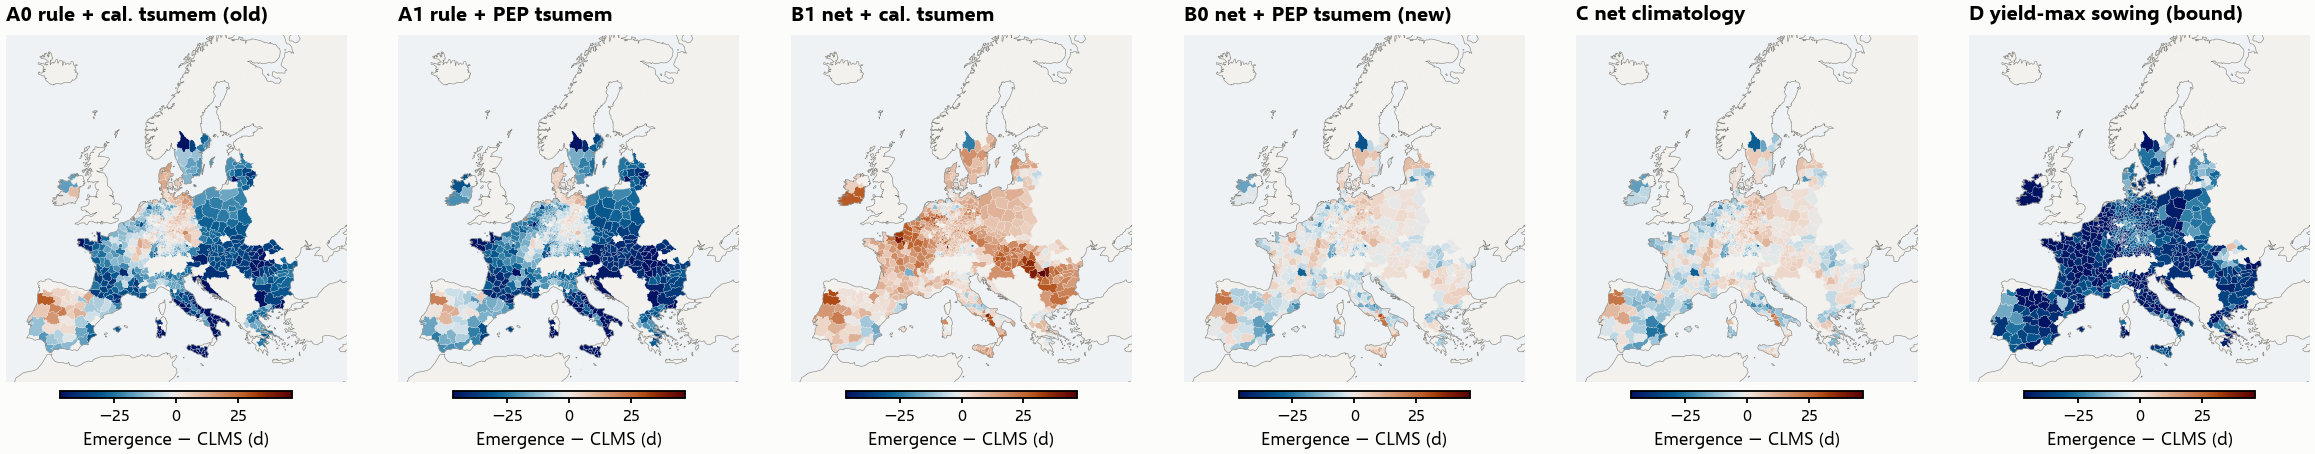

In [8]:
polygons = load_admin_polygons(countries)
fig, axes = plt.subplots(1, len(ARMS), figsize=(3.6 * len(ARMS), 4.2),
                         subplot_kw={"projection": EUROPE_PROJECTION})
limit = float(emer["diff"].abs().quantile(0.95))
for ax, arm in zip(np.atleast_1d(axes), ARMS):
    values = emer[emer["model"] == arm].set_index("adm_id")["diff"]
    country_choropleth(polygons, values, key_col="adm_id", diverging=True, vmax=limit, linewidth=0.1,
                       title=LABELS[arm], cbar_label="Emergence − CLMS (d)", ax=ax)
fig.tight_layout()
save(fig, "emergence_bias_maps", FIGURES)

## 4. Factorial effects and the recalibration check

Climatological medians per arm, then the two main effects and their
interaction:

* **sowing effect** = B1 − A0 (at the calibrated `tsumem`) and B0 − A1 (at the
  PEP725 one);
* **`tsumem` effect** = A1 − A0;
* **interaction** = (B0 − A1) − (B1 − A0).

`tsumem` moves emergence only, so its effect on maturity and yield must be ~0.
The **sowing effect on maturity and yield (B1 − A0)** is the recalibration
check: if maturity shifts by more than ~2 d or yield noticeably, the phenology
and yield stages should be re-fitted on the network's sowing (with
`fixed_parameters: {crop.tsumem: ..., crop.tbasem: ...}` and
`loss.emergence_level: 0`); otherwise the calibrated crops stand.

In [9]:
def arm_medians(column: str, circular: bool) -> pd.Series:
    out = {}
    for arm, frame in runs.items():
        merged = frame[["SimplaceID", "year", column]].merge(
            runs["A0"][["SimplaceID", "year", column]], on=["SimplaceID", "year"], suffixes=("", "_a0"))
        diff = (doy_difference(merged[column].to_numpy(float), merged[f"{column}_a0"].to_numpy(float))
                if circular else merged[column] - merged[f"{column}_a0"])
        out[arm] = float(np.nanmedian(diff))
    return pd.Series(out)


shift = pd.DataFrame({
    "sowing (d)": arm_medians("sowing_doy", True),
    "emergence (d)": arm_medians("emergence_doy", True),
    "maturity (d)": arm_medians("maturity_doy", True),
    "yield (t/ha)": arm_medians("yield_t_ha", False),
}).T.add_prefix("Δ vs A0: ")
shift.to_csv(TABLES / "median_shift_vs_A0.csv")
shift.round(2)

,Δ vs A0: A0,Δ vs A0: A1,Δ vs A0: B1,Δ vs A0: B0,Δ vs A0: C,Δ vs A0: D
sowing (d),0.0,0.00,30.00,30.00,31.00,-5.00
emergence (d),0.0,-5.23,32.80,26.57,28.66,-12.43
maturity (d),0.0,0.00,2.00,2.00,2.00,0.00
yield (t/ha),0.0,0.00,-0.08,-0.06,-0.06,0.05


In [10]:
bias = (pooled[pooled["split"] == "all"].pivot(index="target", columns="model", values="bias")
        .reindex(columns=list(LABELS)))
effects = pd.DataFrame({
    "sowing @ cal. tsumem (B1−A0)": bias["B1"] - bias["A0"],
    "sowing @ PEP tsumem (B0−A1)": bias["B0"] - bias["A1"],
    "tsumem (A1−A0)": bias["A1"] - bias["A0"],
    "weather response (B0−C)": bias["B0"] - bias["C"],
})
effects["interaction"] = effects["sowing @ PEP tsumem (B0−A1)"] - effects["sowing @ cal. tsumem (B1−A0)"]
effects.to_csv(TABLES / "factorial_effects_bias.csv")
effects.round(2)

,sowing @ cal. tsumem (B1−A0),sowing @ PEP tsumem (B0−A1),tsumem (A1−A0),weather response (B0−C),interaction
target,,,,,
emergence,23.68,19.03,-6.19,0.95,-4.64
harvest,1.73,1.62,-0.14,0.18,-0.10
season_length,-22.00,-17.42,6.05,-0.78,4.58
yield,-0.08,-0.07,0.01,-0.00,0.01


## 5. Where in the window each arm sows

Sowing day relative to the SAGE window start. The rule piles up on the
opening day (+1, after the table's latch day); the network should spread
across the window — or beyond it, where SAGE opens too late.

PosixPath('/data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/sowing_comparison/evaluation/figures/sowing_vs_window.png')

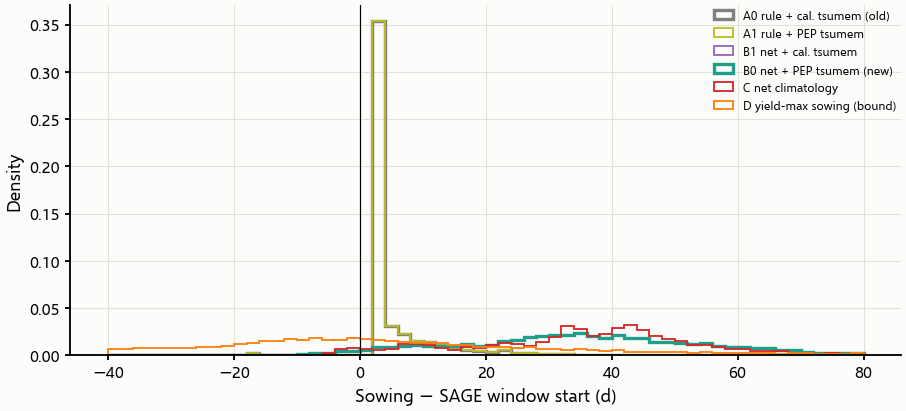

In [11]:
from cropmodelling4eu.export.site import read_site

site = read_site(SOWING.export_dir).frame[["sowing_start_doy"]]
fig, ax = plt.subplots(figsize=(8.5, 4.0))
edges = np.arange(-40, 81, 2)
for arm, frame in runs.items():
    rel = frame["sowing_doy"].to_numpy(float) - frame["SimplaceID"].map(site["sowing_start_doy"]).to_numpy(float)
    ax.hist(rel, bins=edges, histtype="step", lw=2.2 if arm in ("A0", "B0") else 1.2,
            color=COLOURS[arm], density=True, label=LABELS[arm])
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Sowing − SAGE window start (d)", ylabel="Density")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "sowing_vs_window", FIGURES)

## 6. Yield-maximising sowing (arm D, an upper bound)

D runs B0's sowing table shifted by a grid of offsets and keeps, per cell and
season, the offset with the highest **simulated** yield. It knows the season's
whole weather and the model's own yield, so it is not a sowing method: it
bounds how much yield sowing alone can move in torchcrop. Three readings:

* **gain over B0**: if small, sowing is not where the yield error lives;
* **share at the grid edge**: if large, the optimum lies outside the grid and
  the gain is a lower bound on the bound;
* **D's sowing against PEP725** (in §1) and **D's yield against CyBench** (§2):
  if farmers sow far from torchcrop's optimum, or the optimum overshoots the
  observed yield, the model's sowing response is the thing to question.

{'cell_seasons': 1717125, 'at_grid_edge': 0.681, 'median_metric': 3.569596252441406, 'median_gain_vs_offset0': 0.14426483154296887, 'mean_gain_vs_offset0': 0.20231383309384396}


,cell_seasons,median_offset,early_share,median_gain,b0_yield
country,,,,,
AT,9950,-42.0,0.95,0.19,4.68
BE,9450,-42.0,0.97,0.18,6.88
BG,24450,-42.0,0.94,0.22,3.39
CZ,20650,-42.0,0.92,0.24,4.48
DE,107425,-42.0,0.93,0.14,6.41
DK,18225,-42.0,0.88,0.10,6.47
EE,11775,-42.0,0.88,0.11,3.44
EL,15050,-42.0,0.96,0.13,2.55
ES,81450,-42.0,0.90,0.12,2.73


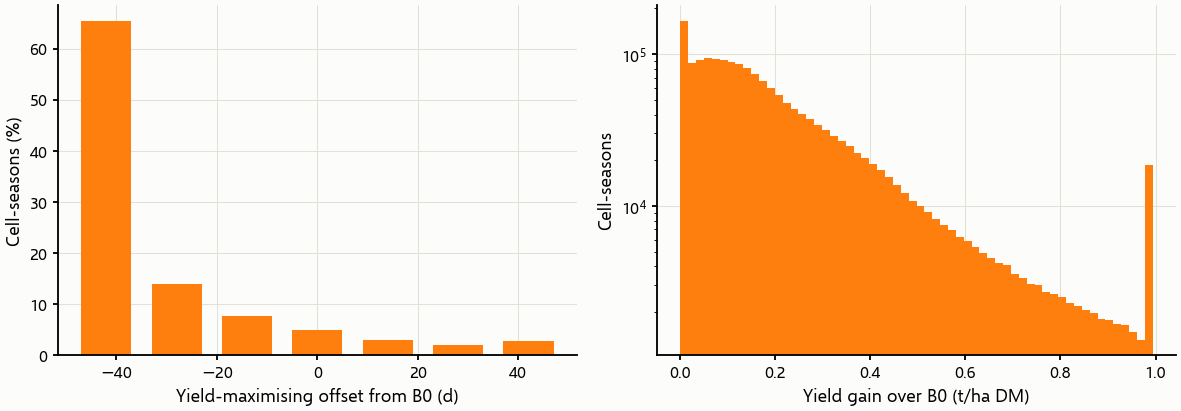

In [12]:
if "D" not in runs:
    print("arm D not finished")
else:
    summary = json.loads((ROOT / "D" / "oracle_summary.json").read_text())
    print({k: summary[k] for k in ("cell_seasons", "at_grid_edge", "median_metric",
                                   "median_gain_vs_offset0", "mean_gain_vs_offset0")})
    cols = ["SimplaceID", "year", "sowing_doy", "yield_t_ha"]
    read = lambda arm, extra=(): (pd.read_parquet(ROOT / arm / "torchcrop" / "torchcrop_europe.parquet",
                                                  columns=[*cols, *extra])
                                  .query("@YEARS[0] <= year <= @YEARS[1]"))
    d = read("D", ["sowing_offset"]).merge(read("B0"), on=["SimplaceID", "year"], suffixes=("", "_b0"))
    d["gain"] = d["yield_t_ha"] - d["yield_t_ha_b0"]
    d["country"] = d["SimplaceID"].map(cell_to_adm.set_index("SimplaceID")["adm_country"])
    by_country = (d.groupby("country")
                  .agg(cell_seasons=("gain", "size"), median_offset=("sowing_offset", "median"),
                       early_share=("sowing_offset", lambda s: (s < 0).mean()),
                       median_gain=("gain", "median"), b0_yield=("yield_t_ha_b0", "median"))
                  .query("cell_seasons >= 500"))
    by_country.to_csv(TABLES / "yield_max_by_country.csv")
    display(by_country.round(2))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    share = pd.Series(summary["offset_share"]).rename(index=int).sort_index()
    axes[0].bar(share.index, 100 * share.values, width=10, color=COLOURS["D"])
    axes[0].set(xlabel="Yield-maximising offset from B0 (d)", ylabel="Cell-seasons (%)")
    axes[1].hist(d["gain"].clip(upper=d["gain"].quantile(0.99)), bins=60, color=COLOURS["D"])
    axes[1].set(xlabel="Yield gain over B0 (t/ha DM)", ylabel="Cell-seasons", yscale="log")
    fig.tight_layout()
    save(fig, "yield_max_sowing", FIGURES)